In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

# Loading all pre-saved data

In [2]:
### PROVIDE scenarios 
# Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). 
    # Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. 
    # Zenodo. https://doi.org/10.5281/zenodo.11108741
# https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description
# https://zenodo.org/records/11108741 for actual data set

folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

### GTPR 2025
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

### Pre-generated interaction matrices from Wunderling 2024
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

## Fitting OS_model to a baeline PROVIDE scenario

In [5]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [3]:
baseline = 'ssp534-over'
baseline_disp = baseline#'SSP5-3.4-OS'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

# Simulations

## Set-up

In [4]:
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

years = np.arange(2015,2301)
no_years=len(years)

pcs = [np.ones((len(p),no_years,len(df_TEs)))*q_c.reshape((1,1,len(df_TEs))) for p in pars]
prs = [np.ones((len(p),no_years,len(df_TEs)))*q_r.reshape((1,1,len(df_TEs))) for p in pars]

temps = [np.zeros((len(pars[i]),no_years)) for i in range(len(popt))]
for i in range(len(popt)):
    PAR = np.copy(popt)
    for j,p_j in enumerate(pars[i]):
        PAR[i] = p_j
        temps[i][j,:] = OS_model(xdata,*PAR)
        for t in range(no_years):
            pcs[i][j,t,:] *= temp_response(temps[i][j,t], T_lim, betas)
            prs[i][j,t,:] *= 1-temp_response(temps[i][j,t], T_lim, betas)

/home/jbara/Code/NMaCh-TP/Code/Notebooks/../util/overshoots.py:180: RuntimeWarning: invalid value encountered in divide
  out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up


## Baseline simulation

In [5]:
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    p_c[t,:] *= temp_response(temp[t], T_lim, betas)
    p_r[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_baseline = np.zeros((len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_years):
        D_baseline[r,:,t] = environmental_update(D_baseline[r,:,t-1],A[r],pc=p_c[t,:],pr=p_r[t,:])

100%|████████████████████████████████████████| 500/500 [00:01<00:00, 375.55it/s]


## Historical data up to 2015 for burn in

In [6]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|█████████████████████████████████████| 165/165 [00:00<00:00, 128995.37it/s]


## Simulations for 2015 onwards

In [7]:
years = np.arange(2015,2301)
no_years=len(years)
D = [np.zeros((len(pars[i]),len_sample,len(df_TEs),no_years)) for i in range(len(popt))]
D_noint = [np.zeros((len(pars[i]),len(df_TEs),no_years)) for i in range(len(popt))]

for i in range(len(popt)):
    for r in range(len_sample):
        D[i][:,r,:,0] = D_burn[r,:]
    D_noint[i][:,:,0] = D_burn_noint[:]

for i in range(len(popt)):
    for j in tqdm.tqdm(range(len(pars[i]))):
        for t in range(1,no_years):
            D_noint[i][j,:,t] = environmental_update(D_noint[i][j,:,t-1],
                                                     np.zeros((len(df_TEs),len(df_TEs))),
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])
            for r in range(len_sample):
                D[i][j,r,:,t] = environmental_update(D[i][j,r,:,t-1],A[r],
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])

100%|███████████████████████████████████████████| 21/21 [00:20<00:00,  1.02it/s]


## Post-simulation analysis (calculating 1-risk)

In [8]:
D_noreef = [np.delete(D[i],6,axis=-2) for i in range(len(popt))]
AR_popt = [k_risk(D_noreef[i],1,axis=2)  
           for i in tqdm.tqdm(range(len(popt)))]

D_nr_noint = [np.delete(D_noint[i],6,axis=-2) for i in range(len(popt))]
AR_popt_noint = [k_risk(D_nr_noint[i],1,axis=1) 
                 for i in tqdm.tqdm(range(len(popt)))]

D_nr_baseline = np.delete(D_baseline,6,axis=1)
AR_baseline = k_risk(D_nr_baseline,1,axis=1)

100%|████████████████████████████████████████████| 6/6 [00:00<00:00, 169.24it/s]


## provide ensemble

In [9]:
def OS_fit(xdata,ydata):
    return curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], 
                           xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]))

In [11]:
baseline = 'ssp534-over'
folder_ensemble = '../../Data/PROVIDE 2025/fair_temperatures/'
df_ensemble = pd.read_csv(folder_ensemble+'scen_%s.csv'%baseline)
df_ensemble=df_ensemble.set_index('year')
years_ensemble = df_ensemble.index.values
temps_ensemble=df_ensemble.to_numpy()

t_ref = 2015
xdata=years_ensemble[t_ref-1850:]-t_ref
popts = np.array([OS_fit(xdata,temps_ensemble[t_ref-1850:,r])[0] for r in range(temps_ensemble.shape[1])])
popt_of_m,_ = OS_fit(xdata,np.median(temps_ensemble[t_ref-1850:,:],axis=1))

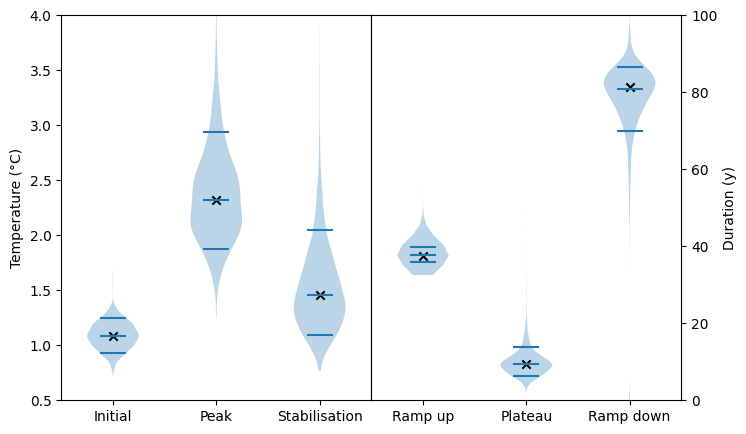

In [21]:
fig,axs=plt.subplots(figsize=(8,5),ncols=2,sharex=False,sharey=False)
fig.subplots_adjust(wspace=0.0)
axs[1].yaxis.set_label_position("right")
axs[1].yaxis.tick_right()

pm=np.median(popts,axis=0)
axs[0].set_xlim(-0.5,2.5)
# axs[0].errorbar(np.arange(3),pm[:3],
#                 yerr=np.abs(np.array([np.quantile(popts[:,:3],q,axis=0) for q in [0.1,0.9]])-pm[:3]),
#                 capsize=5,ls='',marker='x',ms=12)
axs[0].violinplot(popts[:,:3],positions=np.arange(3),showmedians=True,
                  quantiles=[[0.1,0.9]]*3,showextrema=False)
axs[0].set_xticks(np.arange(3),labels=['Initial','Peak','Stabilisation'])
axs[0].set_ylabel('Temperature (°C)')
axs[0].scatter(np.arange(3),popt[:3],marker='x',c='k')
axs[0].set_ylim(0.5,4)
axs[1].set_ylim(0,100)
# axs[0].errorbar()

axs[1].set_xlim(-0.5,2.5)
# axs[1].errorbar(np.arange(3),pm[3:],
#                 yerr=np.abs(np.array([np.quantile(popts[:,3:],q,axis=0) for q in [0.1,0.9]])-pm[3:]),
#                 capsize=5,ls='',marker='x',ms=12)
axs[1].violinplot(popts[:,3:],positions=np.arange(3),
                  showmedians=True,showextrema=False,quantiles=[[0.1,0.9]]*3)
axs[1].set_xticks(np.arange(3),labels=['Ramp up','Plateau','Ramp down'])
axs[1].set_ylabel('Duration (y)')
axs[1].scatter(np.arange(3),popt[3:],marker='x',c='k')
fig.savefig('../../Figures/Overshoots/Conference/%s_parameter_dist.png'%baseline,bbox_inches='tight')

# Plotting

/tmp/ipykernel_413957/1137194336.py:43: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.errorbar(np.deg2rad(angle),p_val,


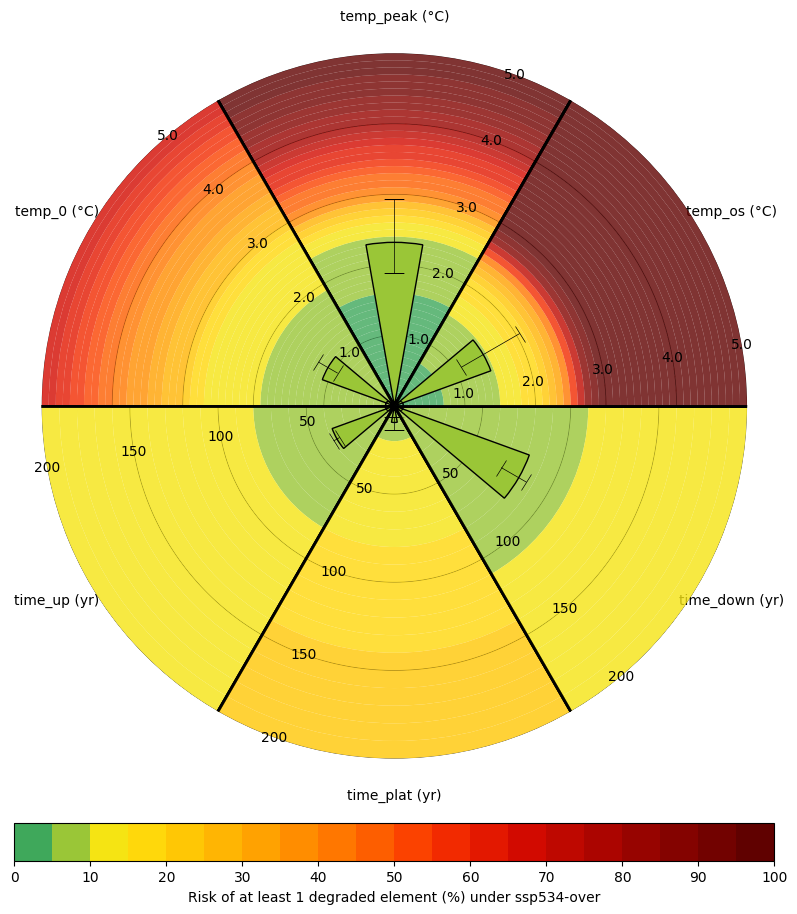

In [16]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=False, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
AR_popt_reordered = list(map(AR_popt.__getitem__, sim2ax_reorder))
pars_reordered = list(map(pars.__getitem__,sim2ax_reorder))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=20)
# bounds = np.arange(-0.5,9,step=1)
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle, pr, p_val in zip(range(len(popt)), 
                            radar.axes, 
                            radar.angles,
                            pars_reordered,
                            popt[sim2ax_reorder]):
    # to_plot = AR_popt_reordered[j].mean(axis=1).max(axis=1) # Picking out the maximum 1-risk
    to_plot = AR_popt_reordered[j].mean(axis=1)[:,-1] # Picking out the final 1-risk

    radar.wedge_stacked_bar(ax,angle,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot,N_col_bins=20,alpha=0.8,edgecolor=None)
    radar.wedge_stacked_bar(ax,angle,[p_val],
                            c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2,N_col_bins=20,
                            c_vals=[AR_baseline.mean(axis=0)[-1]])
    ax.errorbar(np.deg2rad(angle),p_val, 
                yerr=np.array([p_val-np.quantile(popts[:,sim2ax_reorder[j]],0.1),
                      np.quantile(popts[:,sim2ax_reorder[j]],0.9)-p_val]).reshape(2,1),
                c='k',ls='',capsize=7, fmt="-",lw=0.5,capthick=0.5)


radar.draw_wedgeticks(ylims=ylims,width=radar.wedge_width,lw=2)

fig.subplots_adjust(bottom=0.2)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label=r'Risk of at least 1 degraded element (%) under '+baseline_disp,alpha=0.8,
                    )
cbar.set_ticks([k for k in np.arange(0,1.1,0.1)],labels=[k for k in range(0,110,10)])
# rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
# cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'final_1-risk_%s.png'%baseline,bbox_inches='tight')
fig.savefig('../../Figures/Overshoots/Conference/SOS_%s_quantiles.png'%baseline,bbox_inches='tight')

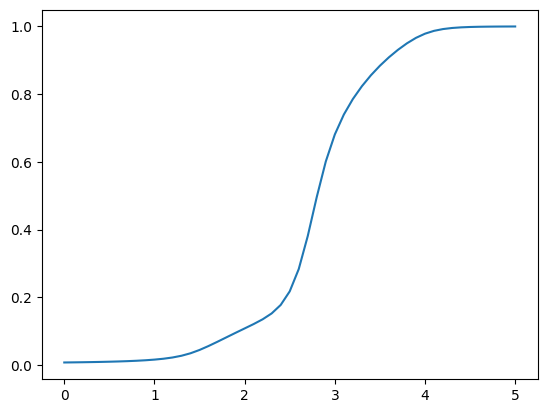

In [31]:
i = 1
plt.plot(pars[i], AR_popt[i].mean(axis=1)[:,-1])

In [15]:
AR_baseline.mean(axis=0)[-1]

np.float64(0.7383363436877759)

# comparisons against interaction-free

In [39]:
AR_popt_noint[0].shape

(51, 286)

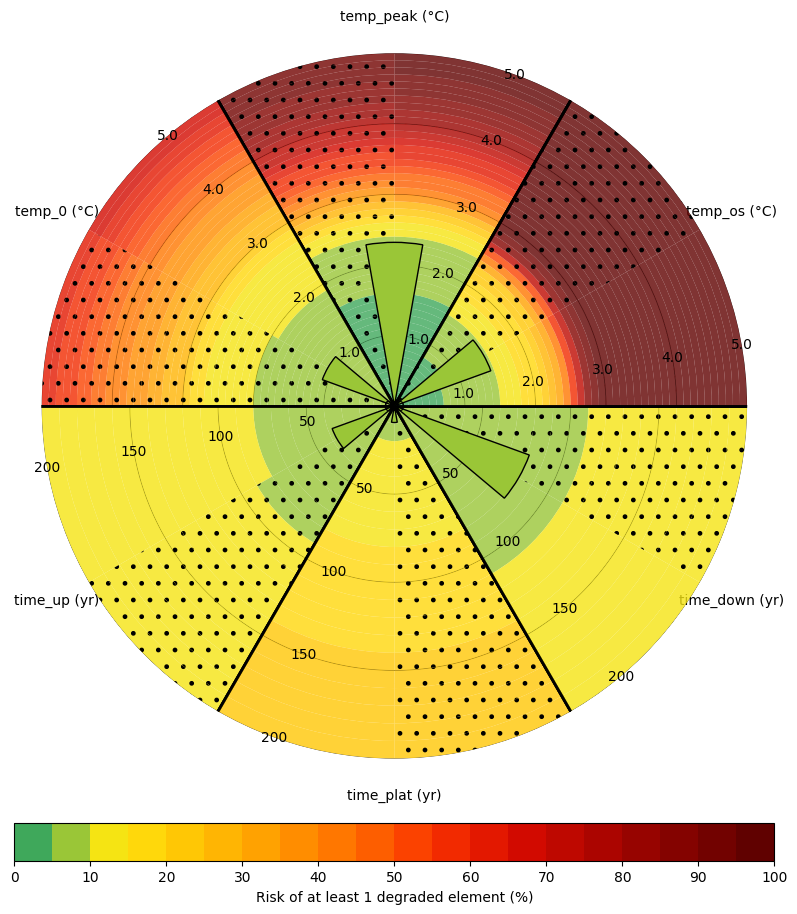

In [43]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=False, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
AR_popt_reordered = list(map(AR_popt.__getitem__, sim2ax_reorder))
AR_popt_noint_reordered = list(map(AR_popt_noint.__getitem__, sim2ax_reorder))
pars_reordered = list(map(pars.__getitem__,sim2ax_reorder))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=20)


for j, ax, angle, pr in zip(range(len(popt)), 
                            radar.axes, 
                            radar.angles,
                            pars_reordered):
    to_plot = AR_popt_reordered[j].mean(axis=1)[:,-1]
    to_plot_noint = AR_popt_noint_reordered[j][:,-1]

    radar.wedge_stacked_bar(ax,angle-90/N,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot,N_col_bins=20,alpha=0.8,
                            edgecolor=None,width=np.deg2rad(outer_width/2))
    radar.wedge_stacked_bar(ax,angle+90/N,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot_noint,N_col_bins=20,alpha=0.8,
                            hatch='.',edgecolor=None,width=np.deg2rad(outer_width/2))
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2,N_col_bins=20,
                            c_vals=[AR_baseline.mean(axis=0).max()])
radar.draw_wedgeticks(ylims=ylims,width=radar.wedge_width,lw=2)
fig.subplots_adjust(bottom=0.2)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label=r'Risk of at least 1 degraded element (%)',alpha=0.8,
                    )
cbar.set_ticks([k for k in np.arange(0,1.1,0.1)],labels=[k for k in range(0,110,10)])

## elementary one-at-a-time (OAT) sensitivity analysis

In [21]:
AR_popt[0].shape

(51, 500, 286)

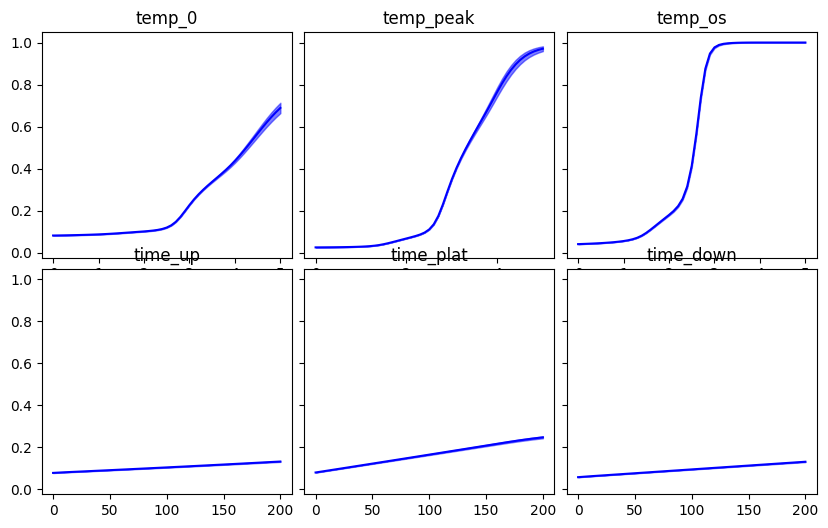

In [27]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    mean=AR_popt[i].mean(axis=1)[:,-1]
    std=AR_popt[i].std(axis=1)[:,-1]
    axs[i//3,i%3].fill_between(pars[i],mean-std,mean+std,color='blue',alpha=0.5)
    axs[i//3,i%3].plot(pars[i],mean,color='blue')
    # for r in range(500):
    #     axs[i//3,i%3].scatter(pars[i],AR_popt[i][:,r,-1],c='k',s=5)

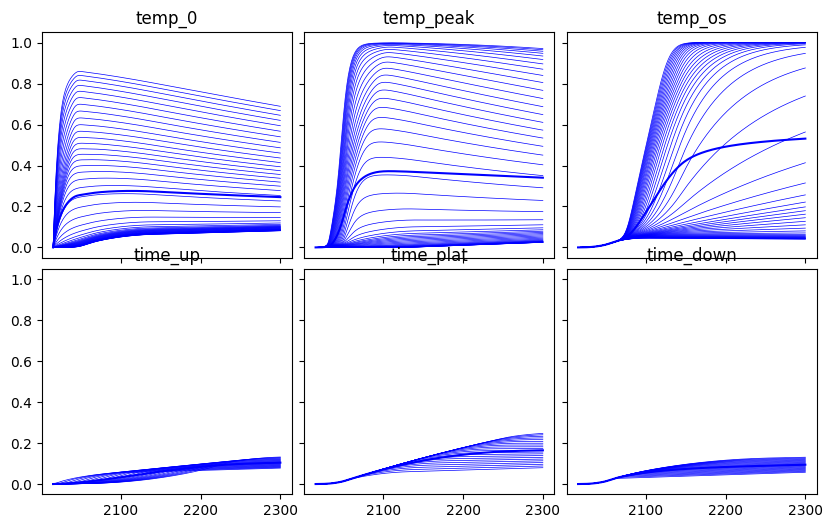

In [33]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True,sharex=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    mean=AR_popt[i].mean(axis=(0,1))
    std=AR_popt[i].std(axis=(0,1))
    # axs[i//3,i%3].fill_between(pars[i],mean-std,mean+std,color='blue',alpha=0.5)
    axs[i//3,i%3].plot(years,mean,color='blue')
    for r in range(AR_popt[i].shape[0]):
        axs[i//3,i%3].plot(years,AR_popt[i].mean(axis=1)[r,:],color='blue',lw=0.5)
    # for r in range(500):
    #     axs[i//3,i%3].scatter(pars[i],AR_popt[i][:,r,-1],c='k',s=5)

In [38]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
       81.42360068])

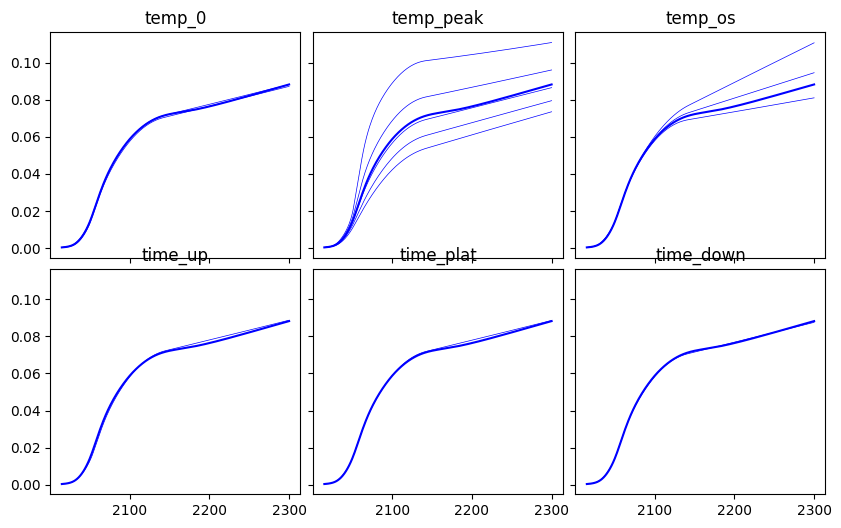

In [39]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True,sharex=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # axs[i//3,i%3].fill_between(pars[i],mean-std,mean+std,color='blue',alpha=0.5)
    axs[i//3,i%3].plot(years,AR_baseline.mean(axis=0)[years[0]-1850:],color='blue')
    for r in range(AR_popt[i].shape[0]):
        if np.abs(pars[i][r]-popt[i])/popt[i] <= 0.1:
            axs[i//3,i%3].plot(years,AR_popt[i].mean(axis=1)[r,:],color='blue',lw=0.5)

## sos in temperature scenario

In [13]:
j=0
pars[j][AR_popt[j].mean(axis=1).max(axis=1)<=0.1].max()

np.float64(1.9000000000000001)

temp_0 0.0 1.9000000000000001
temp_peak 0.0 2.4000000000000004
temp_os 0.0 1.5
time_up 0.0 80.0
time_plat 0.0 20.0
time_down 0.0 110.0


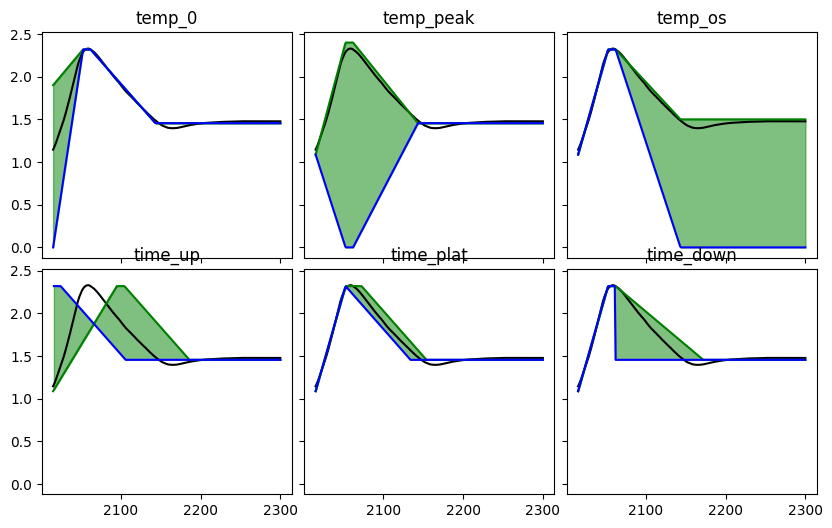

In [35]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True,sharex=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    axs[i//3,i%3].plot(years,temp[years[0]-1850:],color='k')

    PAR_max = np.copy(popt)
    PAR_min = np.copy(popt)
    PAR_max[i] = pars[i][AR_popt[i].mean(axis=1).max(axis=1)<=0.1].max()
    PAR_min[i] = pars[i][AR_popt[i].mean(axis=1).max(axis=1)<=0.1].min()
    print(par_files[i],PAR_min[i],PAR_max[i])
    axs[i//3,i%3].plot(years,OS_model(years-2015,*PAR_max),color='g')
    axs[i//3,i%3].plot(years,OS_model(years-2015,*PAR_min),color='b')
    axs[i//3,i%3].fill_between(years,
                               OS_model(years-2015,*PAR_min),
                               OS_model(years-2015,*PAR_max), color='green',alpha=0.5)

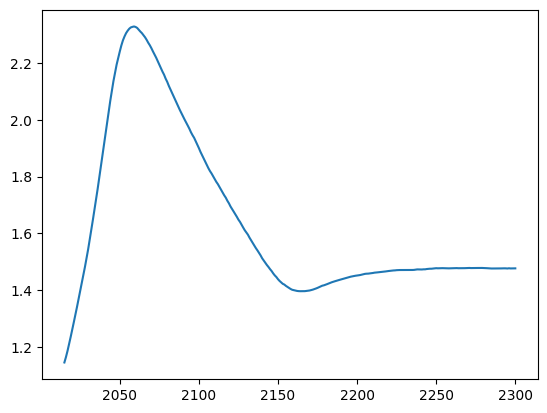

In [31]:
plt.plot(years,temp[years[0]-1850:])

In [23]:
PAR_min

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
        0.        ])

In [17]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
       81.42360068])